# Historico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de diagnósticos

Las [Historico de Bitácoras Onomásticas del Servicio Médico Forense del Distrito Federal (SEMEFO-DF)](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai), han sido sistematizada por la Comisión Nacional de Búsqueda (CNB). Este conjunto de datos se obtuvo a través de una solicitud de acceso a la información disponible en el Portal de Transparencia del Instituto Nacional de acceso a la Información (INAI) en noviembre de 2023 y existe una copia en el portal ciudadano _datamx_ de Codeando México.

El **SEMEFO-DF (Servicio Médico Forense Distrito Federal)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. Las **Bitácoras Onomásticas (BO)** son registros administrativos históricos utilizados por el SEMEFO para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. Estas bitácoras contienen información detallada sobre cada ingreso, como el nombre de la persona fallecida, su edad, sexo, fecha de ingreso, institución de procedencia y diagnóstico preliminar de causa de muerte. En muchos casos, estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Podemos acceder a esta información con la [Plataforma de Transparencia](https://www.plataformadetransparencia.org.mx/Inicio) o en [datamx](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai).

In [1]:
from joblib import load
import pandas as pd
from pandas.api.types import CategoricalDtype

from numpy import nan
from helper_pandas import *
from helper_networkx import *
from unidecode import unidecode

import networkx as nx
from itertools import combinations

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
pd.options.mode.chained_assignment = None 

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
df.tail()

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,46,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,47,...,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,Judicial,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,41,...,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,Hospital,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


In [2]:
from matplotlib.colors import LinearSegmentedColormap

dic_color = {'Poblacion':'#0504aa', 'S-D':'#999999', 'S-D (DF)':'#d9d9d9', 'Masculino':'#377eb8', 'Masculino (DF)':'#80b1d3', 
             'Femenino':'#984ea3', 'Femenino (DF)':'#bebada', 
             'Conocido':'#4daf4a', 'Desconocido':'#dbb40c', 
             'Cadáver conocido':'#04d8b2', 'Cadáver desconocido':'#fdff52', 
             'Recién nacido':'#c875c4', 
             'Feto':'#ff7f00', 
             'Miembros':'#f781bf', 
             'Restos óseos':'#c85a53', }

gray_to_green = LinearSegmentedColormap.from_list('gray_to_green', ['#d9d9d9', '#2a7e19'])


Se llevó a cabo la siguiente selección para su análisis:
* Filtrado de restos óseos y sexo sin datos, por ser de baja frecuencia
* Clasificación con mínimo 200 ocurrencias


In [3]:
df_diag = df.copy()
# Filtrar baja frecuencia tipo y sexo
df_diag = df_diag[ df_diag['Tipo_restos']!='Restos óseos' ]
df_diag['Tipo_restos'] = df_diag['Tipo_restos'].cat.remove_unused_categories()
df_diag = df_diag[ df_diag['Sexo'].isin(['Femenino','Masculino']) ]
df_diag['Sexo'] = df_diag['Sexo'].cat.remove_unused_categories()
# Filtrar diagnósticos con baja frecuecia
thr_col, thr_freq = 'Diagnostico_clasificacion', 200
top_diag = df[thr_col].value_counts()
top_diag = top_diag[top_diag>=thr_freq].index.to_list()
df_diag = df_diag[ df_diag[thr_col].isin(top_diag) ]
df_diag[thr_col] = df_diag[thr_col].astype( CategoricalDtype(categories=top_diag, ordered=True) )
# Categorias
df_diag['Diagnostico_estandar'] = df_diag['Diagnostico_estandar'].cat.remove_unused_categories()
# Resultados operacion
print(f"Diagnosticos seleccionados: {df_diag.shape[0]}/{df['Diagnostico_estandar'].notna().sum()}\n")

Diagnosticos seleccionados: 36313/40943



## Diagnósticos estandar

Frecuencia de diagnósticos estandar

In [4]:
df_cat = pd.read_excel('catalogos/cat_diag_sustitucion.xlsx')
df_cat = df_cat.groupby('Diagnostico_estandar').agg(
                        {'Diagnostico_extendido':'first',
                        'freq':'sum', 'Npartes':'first', 'Nfalta':'first'}) \
               .sort_values('freq', ascending=False)
df_cat.head(25)

,Diagnostico_extendido,freq,Npartes,Nfalta
Diagnostico_estandar,,,,
S-D,sin datos,55901,1,0
TM,traumatismo multiple,7525,1,0
TCE,traumatismo craneo encefalico,5992,1,0
BN,bronconeumonia,1856,1,0
CVG,congestion visceral generalizada,1329,1,0
TCT,traumatismo craneo torax,1185,1,0
HPAF,herida arma fuego,1001,1,0
HPAFC,herida arma fuego craneo,944,1,0
Dispensa,dispensa,921,1,0


Partes por diagnóstico

In [5]:
df_cat.groupby('Npartes')['freq'].agg(['sum','count'])

,sum,count
Npartes,,
1,89999,534
2,6448,1373
3,356,298
4,38,36
5,3,3


Partes sin resolver por diagnóstico

In [6]:
df_cat.groupby('Nfalta')['freq'].agg(['sum','count'])

,sum,count
Nfalta,,
0,95390,999
1,1317,1108
2,126,126
3,11,11


Gráfica resumen

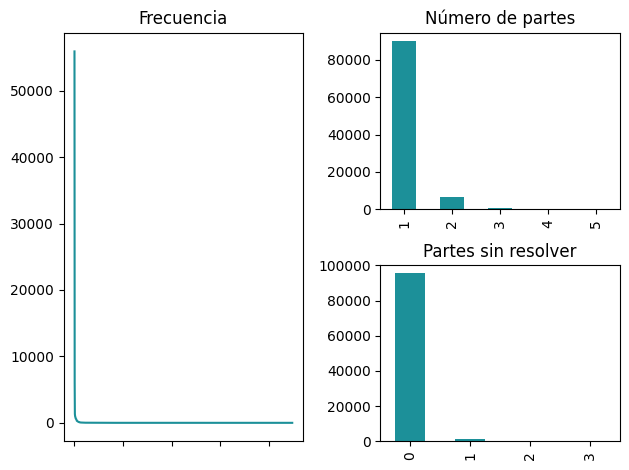

In [7]:
# Create a figure and a custom grid specification
fig = plt.figure()
gs = fig.add_gridspec(2, 2)
# Create subplots
ax1 = fig.add_subplot(gs[:, 0]) # All rows, first column
ax1 = df_cat['freq'].plot(ax=ax1, title='Frecuencia', xlabel='', color='#1c9099')
ax1.set_xticklabels([])
ax2 = fig.add_subplot(gs[0, 1]) # First row, second column
ax2 = df_cat.groupby('Npartes')['freq'].sum() \
            .plot.bar(ax=ax2, title='Número de partes', xlabel='', color='#1c9099')
ax3 = fig.add_subplot(gs[1, 1]) # Second row, second column
ax3 = df_cat.groupby('Nfalta')['freq'].sum() \
            .plot.bar(ax=ax3, title='Partes sin resolver', xlabel='', color='#1c9099')
# Adjust layout and plot
plt.tight_layout()
plt.show()

### Red de diagnosticos

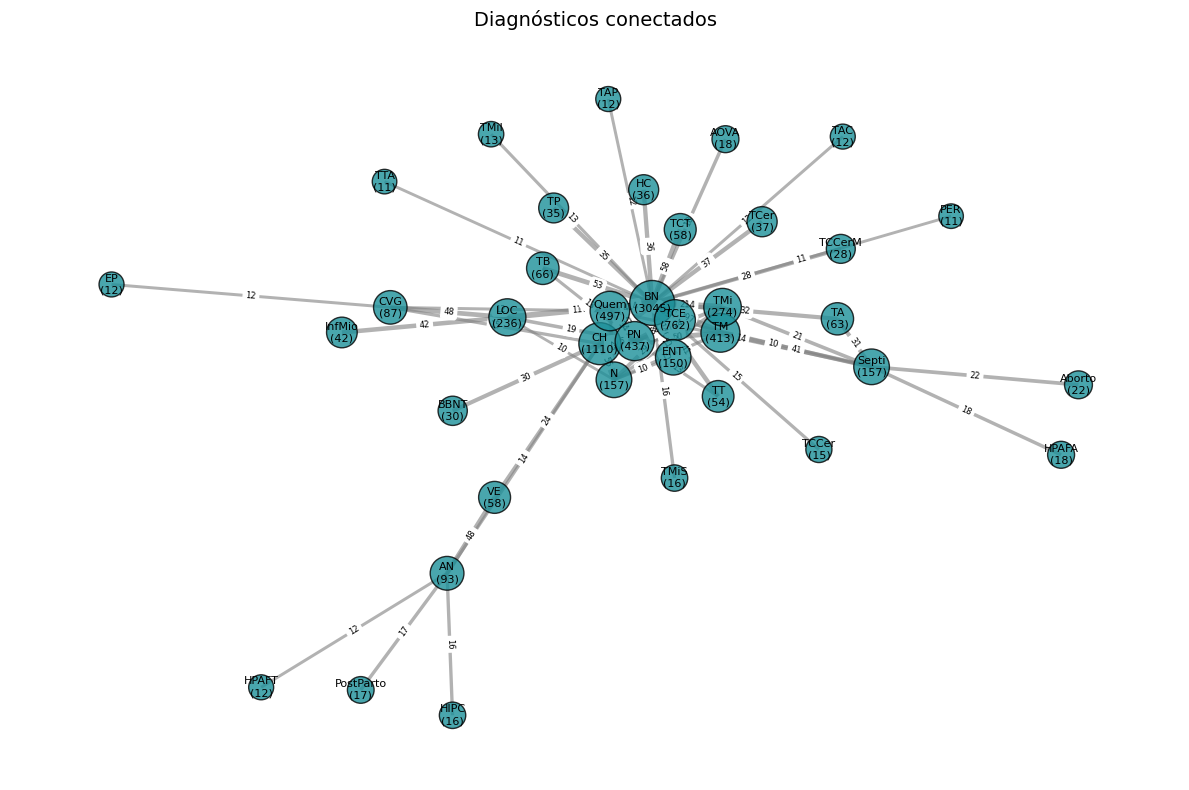

In [8]:
data = df_diag['Diagnostico_estandar'].value_counts()
data = data[data>=10]
data.to_list()
G = create_network_from_lists(data.index.to_list(), data.to_list(), sep='+')

# Obtain log10 of weight
for node in G.nodes():
    G.nodes[node]["weight_log10"] = float(np.log10( G.nodes[node]["weight"] ))
for node1, node2 in G.edges():
    G.edges[node1, node2]["weight_log10"] = float(np.log10( G.edges[node1, node2]["weight"] ))
#print_graph_output(G)

# Plot the graph
plot_weighted_graph(
                    G, plot_title="Diagnósticos conectados", 
                    node_color='#1c9099', font_size=8,
                    node_size_attribute='weight_log10', edge_width_attribute='weight_log10',
                    node_label_attribute='weight', edge_label_attribute='weight',
                    )
#export_graph_to_graphml(G, 'data_clean/HBO_diag_graph.graphml')

## Diagnósticos por clasificación


Principales diagnósticos por clasificación

In [9]:
data = df_diag.groupby('Diagnostico_clasificacion').agg(
            Freq=('Diagnostico_estandar', 'size'), 
            Top=('Diagnostico_estandar', top_values_of_series_to_string),
            )
data = data.sort_values('Freq', ascending=False).reset_index()
data

,Diagnostico_clasificacion,Freq,Top
0,Trauma,20173,"TM (7524), TCE (5988), TCT (1185), BN+TCE (635..."
1,Causas externas de morbilidad y de mortalidad,4497,"Quem (816), AOVA (809), AXA (564), ASB (540), ..."
2,Herida por arma de fuego,3389,"HPAF (1001), HPAFC (943), HPAFPT (601), HPAFA ..."
3,Enfermedades del sistema respiratorio,2387,"BN (1854), PN (234), N (129), EP (46), BBNT (45)"
4,Enfermedades del sistema digestivo,1772,"BN+CH (800), CH+PN (186), CH (158), BN+ENT (14..."
5,"Embarazo, parto y puerperio",1198,"ANEN (563), EXPSM (498), FCPN (27), Aborto+Sep..."
6,Enfermedades del sistema circulatorio,988,"LOC (672), BN+LOC (117), CVG+LOC (48), InfMio+..."
7,Herida punzo cortante,867,"HIPCT (287), HIPC (261), HIPCTA (93), HIPCPA (..."
8,Amputación,688,"AQXT (605), AT (28), AQ (12), AQXTMi (7), AQXT..."
9,Ciertas enfermedades infecciosas y parasitarias,354,"TB (204), BN+TB (53), Septi (43), PN+TB (13), ..."


## Diagnóstico por tipo y sexo

Tipo_restos                                     Cadáver conocido  \
Sexo                                                    Femenino   
Diagnostico_clasificacion                                          
Trauma                                             4042 (61.19%)   
Causas externas de morbilidad y de mortalidad      1129 (17.09%)   
Herida por arma de fuego                             301 (4.56%)   
Enfermedades del sistema respiratorio                511 (7.74%)   
Enfermedades del sistema digestivo                   219 (3.32%)   
Embarazo, parto y puerperio                           93 (1.41%)   
Enfermedades del sistema circulatorio                194 (2.94%)   
Herida punzo cortante                                 60 (0.91%)   
Amputación                                             3 (0.05%)   
Ciertas enfermedades infecciosas y parasitarias       54 (0.82%)   

Tipo_restos                                                      \
Sexo                                                  Masculino   
Diagnostico_clasificacion                                         
Trauma                                           13206 (59.51%)   
Causas externas de morbilidad y de mortalidad     2822 (12.72%)   
Herida por arma de fuego                           2819 (12.7%)   
Enfermedades del sistema respiratorio              1008 (4.54%)   
Enfermedades del sistema digestivo                  812 (3.66%)   
Embarazo, parto y puerperio                          12 (0.05%)   
Enfermedades del sistema circulatorio               635 (2.86%)   
Herida punzo cortante                               705 (3.18%)   
Amputación                                           13 (0.06%)   
Ciertas enfermedades infecciosas y parasitarias     158 (0.71%)   

Tipo_restos                                     Cadáver desconocido  \
Sexo                                                       Femenino   
Diagnostico_clasificacion                                             
Trauma                                                 358 (50.92%)   
Causas externas de morbilidad y de mortalidad           93 (13.23%)   
Herida por arma de fuego                                 22 (3.13%)   
Enfermedades del sistema respiratorio                  114 (16.22%)   
Enfermedades del sistema digestivo                       70 (9.96%)   
Embarazo, parto y puerperio                              18 (2.56%)   
Enfermedades del sistema circulatorio                     19 (2.7%)   
Herida punzo cortante                                     2 (0.28%)   
Amputación                                                            
Ciertas enfermedades infecciosas y parasitarias            7 (1.0%)   

Tipo_restos                                                    Recién nacido  \
Sexo                                                 Masculino      Femenino   
Diagnostico_clasificacion                                                      
Trauma                                           2474 (51.09%)   11 (12.94%)   
Causas externas de morbilidad y de mortalidad       368 (7.6%)   15 (17.65%)   
Herida por arma de fuego                           240 (4.96%)                 
Enfermedades del sistema respiratorio             711 (14.68%)   11 (12.94%)   
Enfermedades del sistema digestivo                658 (13.59%)     3 (3.53%)   
Embarazo, parto y puerperio                         25 (0.52%)   45 (52.94%)   
Enfermedades del sistema circulatorio              135 (2.79%)                 
Herida punzo cortante                               98 (2.02%)                 
Amputación                                           2 (0.04%)                 
Ciertas enfermedades infecciosas y parasitarias    131 (2.71%)                 

Tipo_restos                                                           Feto  \
Sexo                                               Masculino      Femenino   
Diagnostico_clasificacion                                                    
Trauma                                      

Text(0.5, 1.0, 'Ingresos por diagnóstico, tipo restos y sexo')

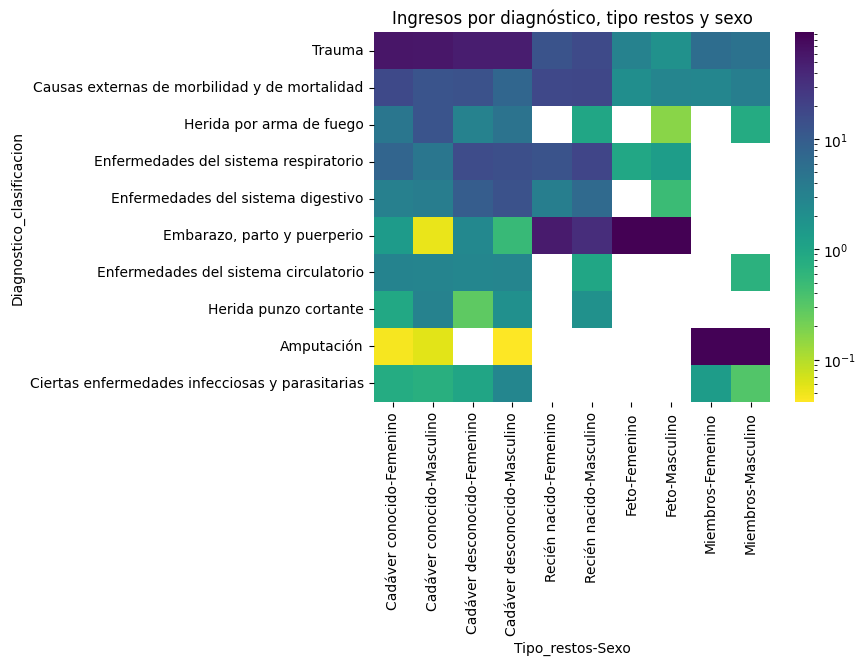

In [10]:
data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns=['Tipo_restos','Sexo'], values='Diagnostico_estandar', aggfunc='count')
data_per = (data/data.sum()*100).replace(0,nan)
data_annot = (data.astype(str) + " (" + data_per.round(2).astype(str) + "%)").replace('0 (nan%)','')
display( data_annot )
# Plot
log_norm = LogNorm(vmin=data_per.min().min(), vmax=data_per.max().max())
plt.figure()
sns.heatmap(data_per, norm=log_norm, cmap='viridis_r')
plt.title('Ingresos por diagnóstico, tipo restos y sexo')

Revisando diagnósticos con discrepancia de género

In [11]:
col_tran = [c for c in df_diag.columns if 'transcrito' in c]
df_diag.loc[(df_diag['Diagnostico_clasificacion']=='Embarazo, parto y puerperio')&(df_diag['Sexo']=='Masculino'), col_tran]

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Fecha_transcrito,Edad_transcrito,Diagnostico_transcrito,Procedencia_transcrito,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Foja_transcrito
ID,,,,,,,,,
BO_1974_03518,S-D,parkansi flores,1974-08-30,5 días,ANN,19a,755,4129,70
BO_1974_03633,20,quinino medina sin nombre,1974-09-04,[8],ANEN,27a,646,4244,73
BO_1974_04767,341,desconocido,1974-06-08,7.5,ANN,15a,1351,2776,115
BO_1974_05303,6,feto,1974-01-12,5 meses,EX PSM,20a,26,191,140
BO_1974_05304,7,feto,1974-01-14,9 meses,ANN,9a,65,212,140
...,...,...,...,...,...,...,...,...,...
BO_1979_07196,S-D,recien nacido,1979-01-25,-72,ANEN,35a,159,515,145
BO_1979_07206,S-D,recien nacido,1979-04-29,-72,ANEN,24a,1050,2418,145
BO_1979_07209,S-D,nombre confidencial,1979-05-29,-72,ANEON,1a,1793,3032,145


Principales diagnósticos por sexo

In [12]:
top_ = lambda s: top_values_of_series_to_string(s,thr_min=10)
data = df_diag.pivot_table(
    index='Diagnostico_clasificacion',
    columns=['Tipo_restos','Sexo'],
    values='Diagnostico_estandar',
    aggfunc=top_,
    
)
top_diag = df_diag['Diagnostico_clasificacion'].value_counts()
data = pd.concat([top_diag,data,], axis=1).sort_values('count', ascending=False)
data

,count,"(Cadáver conocido, Femenino)","(Cadáver conocido, Masculino)","(Cadáver desconocido, Femenino)","(Cadáver desconocido, Masculino)","(Recién nacido, Femenino)","(Recién nacido, Masculino)","(Feto, Femenino)","(Feto, Masculino)","(Miembros, Femenino)","(Miembros, Masculino)"
Diagnostico_clasificacion,,,,,,,,,,,
Trauma,20173,"TM (1542), TCE (1098), TCT (248), BN+TMi (98),...","TM (4545), TCE (4090), TCT (781), BN+TCE (495)...","TM (202), TCE (81), TCT (15)","TM (1224), TCE (693), TCT (141), BN+TCE (47), ...",NaN,NaN,NaN,NaN,NaN,TMi (26)
Causas externas de morbilidad y de mortalidad,4497,"Quem (257), HC (185), AOVA (165), BN+Quem (140...","AOVA (513), Quem (477), AXA (448), ASB (354), ...","Quem (19), AOVA (17), AE (16), HC (11), ASB (11)","AOVA (107), ASB (69), Quem (57), AXA (33), HC ...",NaN,AE (10),NaN,NaN,NaN,NaN
Herida por arma de fuego,3389,"HPAFC (116), HPAF (69), HPAFPT (48), HPAFA (31...","HPAF (845), HPAFC (752), HPAFPT (504), HPAFA (...",HPAF (11),"HPAF (72), HPAFC (68), HPAFPT (48), HPAFA (14)...",NaN,NaN,NaN,NaN,NaN,NaN
Enfermedades del sistema respiratorio,2387,"BN (400), PN (32), N (28), EP (14), BBNT (11)","BN (747), PN (105), N (70), EP (29), InfPul (22)",BN (98),"BN (576), PN (90), N (26), BBNT (11)",BN (10),BN (19),NaN,NaN,NaN,NaN
Enfermedades del sistema digestivo,1772,"BN+CH (54), BN+ENT (34), CH (22), Gastroent (1...","BN+CH (320), CH+PN (84), CH (71), BN+ENT (59),...","BN+CH (39), BN+ENT (17)","BN+CH (386), CH+PN (86), CH (62), BN+ENT (22),...",NaN,NaN,NaN,NaN,NaN,NaN
"Embarazo, parto y puerperio",1198,"Aborto+Septi (20), AN+PostParto (16)",NaN,NaN,ANEN (16),ANEN (40),ANEN (35),"ANEN (196), EXPSM (186), FCPN (11)","EXPSM (304), ANEN (257)",NaN,NaN
Enfermedades del sistema circulatorio,988,"LOC (123), BN+LOC (18), InfMio+LOC (14)","LOC (444), BN+LOC (75), CVG+LOC (32), InfMio+L...",LOC (11),"LOC (93), BN+LOC (21)",NaN,NaN,NaN,NaN,NaN,NaN
Herida punzo cortante,867,"HIPC (21), HIPCT (11)","HIPCT (236), HIPC (215), HIPCTA (69), HIPCPA (...",NaN,"HIPCT (39), HIPC (23), HIPCTA (15)",NaN,NaN,NaN,NaN,NaN,NaN
Amputación,688,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AQXT (112),"AQXT (483), AT (22)"


## Diagnóstico por grupo de edad

Edad_grupo,"[0, 1)","[1, 5)","[5, 10)","[10, 15)","[15, 20)","[20, 25)","[25, 30)","[30, 35)","[35, 40)","[40, 45)","[45, 50)","[50, 55)","[55, 60)","[60, 65)","[65, 70)","[70, 75)","[75, 80)","[80, 85)","[85, 110)"
Diagnostico_clasificacion,,,,,,,,,,,,,,,,,,,
Trauma,238 (10.62%),874 (50.93%),1019 (78.99%),821 (72.4%),1226 (57.59%),1882 (55.3%),2042 (59.05%),1543 (56.25%),1663 (57.8%),1377 (55.73%),1381 (57.64%),1262 (59.47%),916 (58.57%),1011 (60.98%),885 (61.84%),824 (60.32%),598 (65.86%),304 (64.27%),263 (67.96%)
Causas externas de morbilidad y de mortalidad,362 (16.15%),675 (39.34%),177 (13.72%),191 (16.84%),331 (15.55%),413 (12.14%),353 (10.21%),318 (11.59%),298 (10.36%),249 (10.08%),233 (9.72%),203 (9.57%),155 (9.91%),125 (7.54%),121 (8.46%),110 (8.05%),89 (9.8%),24 (5.07%),41 (10.59%)
Herida por arma de fuego,9 (0.4%),22 (1.28%),37 (2.87%),59 (5.2%),369 (17.33%),715 (21.01%),645 (18.65%),432 (15.75%),336 (11.68%),215 (8.7%),188 (7.85%),96 (4.52%),82 (5.24%),51 (3.08%),53 (3.7%),43 (3.15%),18 (1.98%),9 (1.9%),4 (1.03%)
Enfermedades del sistema respiratorio,363 (16.2%),94 (5.48%),18 (1.4%),29 (2.56%),37 (1.74%),66 (1.94%),88 (2.54%),127 (4.63%),172 (5.98%),220 (8.9%),212 (8.85%),188 (8.86%),131 (8.38%),171 (10.31%),126 (8.81%),151 (11.05%),83 (9.14%),68 (14.38%),40 (10.34%)
Enfermedades del sistema digestivo,175 (7.81%),38 (2.21%),10 (0.78%),4 (0.35%),13 (0.61%),30 (0.88%),60 (1.74%),122 (4.45%),226 (7.86%),238 (9.63%),212 (8.85%),182 (8.58%),126 (8.06%),118 (7.12%),80 (5.59%),78 (5.71%),30 (3.3%),20 (4.23%),9 (2.33%)
"Embarazo, parto y puerperio",1076 (48.01%),1 (0.06%),16 (1.24%),1 (0.09%),11 (0.52%),23 (0.68%),25 (0.72%),15 (0.55%),8 (0.28%),8 (0.32%),3 (0.13%),1 (0.05%),,,,7 (0.51%),,,
Enfermedades del sistema circulatorio,6 (0.27%),3 (0.17%),1 (0.08%),7 (0.62%),10 (0.47%),15 (0.44%),27 (0.78%),31 (1.13%),45 (1.56%),55 (2.23%),82 (3.42%),117 (5.51%),97 (6.2%),116 (7.0%),121 (8.46%),121 (8.86%),74 (8.15%),37 (7.82%),20 (5.17%)
Herida punzo cortante,3 (0.13%),2 (0.12%),5 (0.39%),7 (0.62%),100 (4.7%),205 (6.02%),170 (4.92%),110 (4.01%),77 (2.68%),53 (2.14%),44 (1.84%),30 (1.41%),22 (1.41%),11 (0.66%),10 (0.7%),11 (0.81%),2 (0.22%),1 (0.21%),2 (0.52%)
Amputación,1 (0.04%),3 (0.17%),6 (0.47%),9 (0.79%),31 (1.46%),37 (1.09%),36 (1.04%),19 (0.69%),13 (0.45%),16 (0.65%),10 (0.42%),6 (0.28%),9 (0.58%),14 (0.84%),9 (0.63%),5 (0.37%),5 (0.55%),3 (0.63%),4 (1.03%)


Text(0.5, 1.0, 'Ingresos por diagnóstico y grupo de edad')

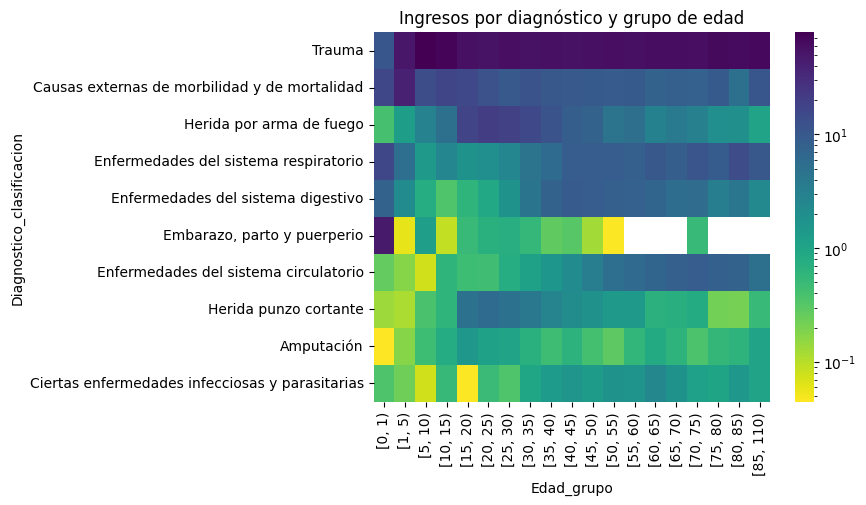

In [13]:
data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns='Edad_grupo', values='Diagnostico_estandar', aggfunc='count')
data_per = (data/data.sum()*100).replace(0,nan)
data_annot = (data.astype(str) + " (" + data_per.round(2).astype(str) + "%)").replace('0 (nan%)','')
display( data_annot )
# Plot
log_norm = LogNorm(vmin=data_per.min().min(), vmax=data_per.max().max())
plt.figure()
sns.heatmap(data_per, norm=log_norm, cmap='viridis_r')
plt.title('Ingresos por diagnóstico y grupo de edad')

Principales diagnósticos por clasificación

In [14]:
top_ = lambda s: top_values_of_series_to_string(s,thr_min=10)
data = df_diag.pivot_table(
    index='Diagnostico_clasificacion',
    columns='Edad_grupo',
    values='Diagnostico_estandar',
    aggfunc=top_,
    
)
top_diag = df_diag['Diagnostico_clasificacion'].value_counts()
data = pd.concat([top_diag,data,], axis=1).sort_values('count', ascending=False)
data

,count,"[0, 1)","[1, 5)","[5, 10)","[10, 15)","[15, 20)","[20, 25)","[25, 30)","[30, 35)","[35, 40)","[40, 45)","[45, 50)","[50, 55)","[55, 60)","[60, 65)","[65, 70)","[70, 75)","[75, 80)","[80, 85)","[85, 110)"
Diagnostico_clasificacion,,,,,,,,,,,,,,,,,,,,
Trauma,20173,"TCE (154), TM (28), BN+TCE (10)","TCE (320), TM (276), TCT (52), TTA (34), TAC (31)","TM (370), TCE (342), TCT (61), TAC (32), TTA (30)","TM (323), TCE (256), TCT (46), TAC (25), TTA (23)","TCE (429), TM (424), TCT (69), BN+TCE (25), TT...","TM (706), TCE (591), TCT (92), BN+TCE (57), TT...","TM (842), TCE (603), TCT (88), TTA (63), BN+TC...","TM (630), TCE (436), TCT (85), TTA (45), BN+TC...","TM (672), TCE (459), TCT (92), BN+TCE (49), TT...","TM (556), TCE (406), TCT (77), BN+TCE (43), TT...","TM (527), TCE (425), TCT (86), BN+TCE (41), TT...","TM (463), TCE (361), TCT (80), BN+TCE (51), TT...","TM (344), TCE (270), TCT (77), BN+TCE (29), TT...","TM (384), TCE (267), TCT (66), BN+TCE (29), BN...","TM (317), TCE (211), TCT (60), BN+TCE (40), TT...","TM (292), TCE (200), TCT (65), BN+TCE (48), BN...","TM (204), TCE (124), TCT (39), BN+TCE (30), BN...","TM (89), TCE (72), TCT (26), BN+TMi (24), BN+T...","TM (68), TCE (57), BN+TMi (25), TCT (16), BN+T..."
Causas externas de morbilidad y de mortalidad,4497,"AOVA (152), Quem (66), AE (24), BN+Quem (23), ...","Quem (211), ASB (156), BN+Quem (155), AOVA (67...","Quem (47), ASB (33), BN+Quem (29), AOVA (25)","ASB (46), AXA (30), Quem (27), AOVA (22), BN+Q...","AXA (67), ASB (58), AOVA (47), Quem (40), Elec...","AXA (120), ASB (62), Quem (57), AOVA (34), BN+...","AXA (87), Quem (78), ASB (39), AOVA (37), Elec...","Quem (56), AXA (54), AOVA (49), HC (30), ASB (28)","AOVA (65), AXA (41), Quem (37), ASB (34), HC (32)","AOVA (55), AXA (40), Quem (37), HC (33), BN+Qu...","AOVA (70), HC (40), Quem (30), AXA (20), ASB (12)","AOVA (57), HC (41), AXA (28), Quem (12), ASB (11)","AOVA (42), HC (32), Quem (21), AXA (19)","AOVA (32), HC (31), Quem (21), AXA (10)","HC (36), AOVA (22), Quem (19), AXA (13)","HC (36), Quem (21), AOVA (12)","HC (26), Quem (20), AOVA (13)",NaN,HC (13)
Herida por arma de fuego,3389,NaN,HPAFC (12),HPAFC (19),"HPAFC (25), HPAF (14), HPAFPT (14)","HPAFC (100), HPAF (98), HPAFPT (84), HPAFA (34...","HPAF (227), HPAFC (173), HPAFPT (142), HPAFA (...","HPAF (204), HPAFC (166), HPAFPT (114), HPAFA (...","HPAFC (129), HPAF (128), HPAFPT (62), HPAFTA (...","HPAF (106), HPAFC (79), HPAFPT (58), HPAFTA (3...","HPAF (62), HPAFC (57), HPAFPT (37), HPAFA (23)...","HPAFC (52), HPAF (41), HPAFPT (33), HPAFA (29)...","HPAF (34), HPAFC (32), HPAFPT (11)","HPAFC (26), HPAF (25), HPAFPT (10)","HPAF (15), HPAFC (14), HPAFPT (10)","HPAFC (21), HPAF (16)",HPAFC (23),NaN,NaN,NaN
Enfermedades del sistema respiratorio,2387,"BN (333), N (13)",BN (80),BN (15),BN (19),BN (21),BN (44),BN (60),"BN (96), PN (17)","BN (123), PN (28)","BN (158), PN (31), N (18)","BN (175), PN (14), N (13)","BN (148), PN (22), N (11)","BN (90), PN (16)","BN (122), PN (24), N (11)","BN (94), PN (18)","BN (119), PN (16)",BN (66),BN (54),BN (34)
Enfermedades del sistema digestivo,1772,"BN+ENT (114), Gastroent (16), ENT (15)",BN+ENT (16),NaN,NaN,NaN,BN+CH (14),BN+CH (18),"BN+CH (55), CH (18), CH+PN (16), Pancrea (10)","BN+CH (105), CH+PN (28), CH (25), CH+N (12)","BN+CH (127), CH (31), CH+PN (31)","BN+CH (112), CH+PN (31), CH (21)","BN+CH (103), CH (22), CH+PN (12)","BN+CH (70), CH+PN (17), CH (11)","BN+CH (78), CH+PN (14)","BN+CH (39), CH+PN (10)","BN+CH (42), CH+PN (13)",BN+CH (12),NaN,NaN
"Embarazo, parto y puerperio",1198,"ANEN (546), EXPSM (493), FCPN (25)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Enfermedades del sistema circulatorio,988,NaN,NaN,NaN,NaN,NaN,NaN,LOC (16),LOC (18),LOC (32),LOC (38),"LOC (57), BN+LOC (11)","LOC (81), BN+LOC (14)",LOC (66),LOC (80),"LOC (84), BN+LOC (10)","LOC (87), BN+LOC (14)","LOC (52), BN+LOC (15)","LOC (24), BN+LOC (10)",LOC (14)
Herida punzo cortante,867,NaN,NaN,NaN,NaN,"HIPCT (34), HIP

## Red palabras por clasificación

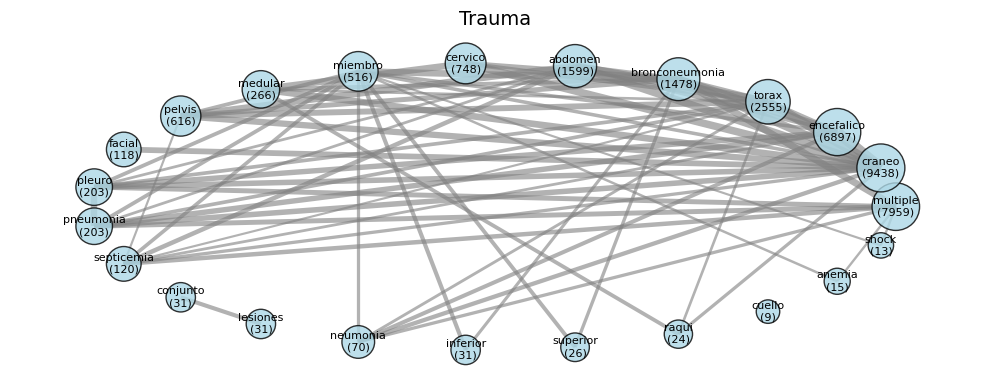

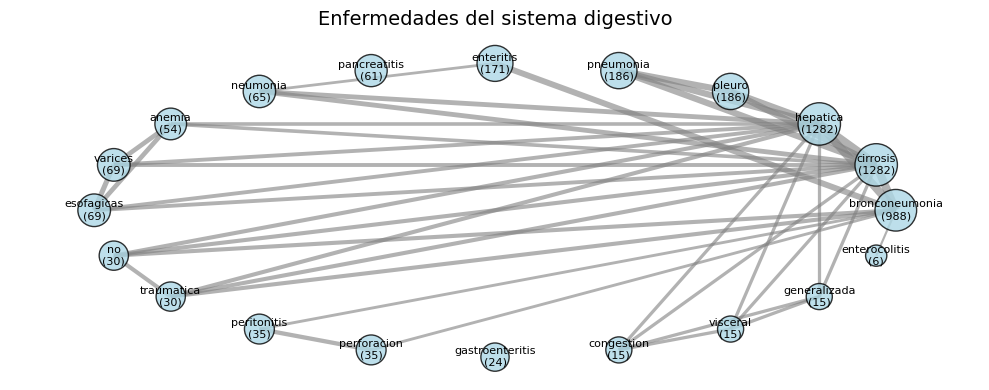

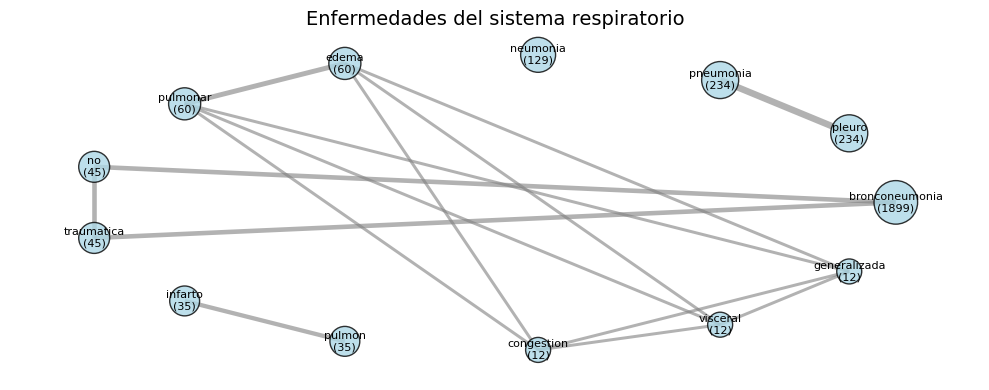

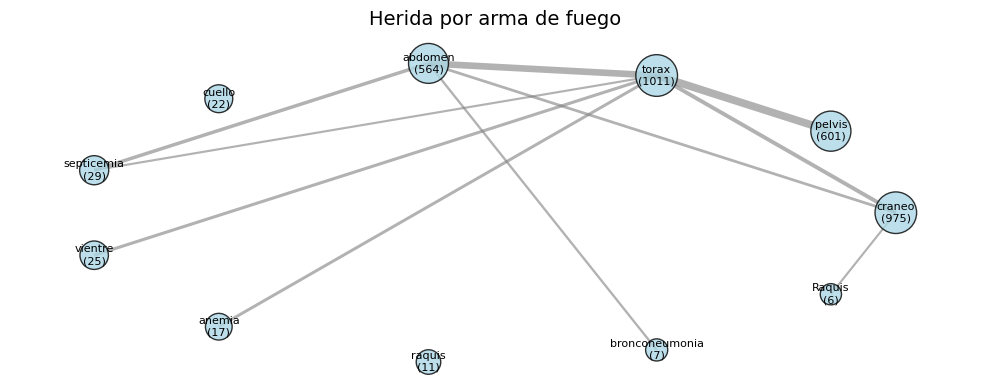

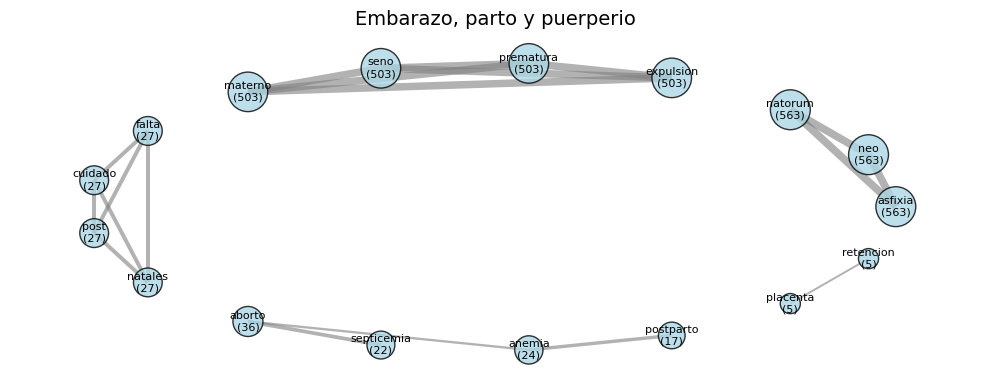

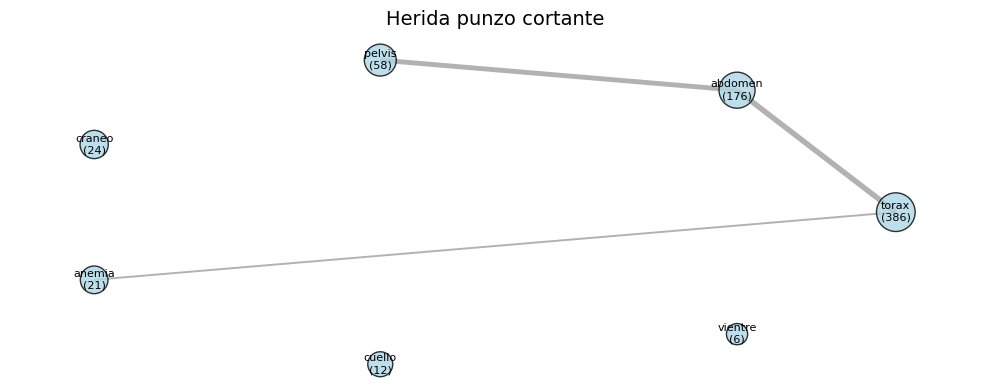

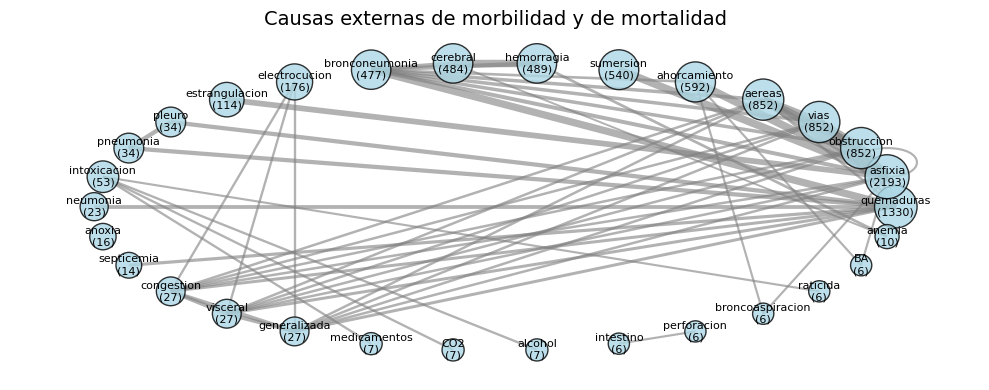

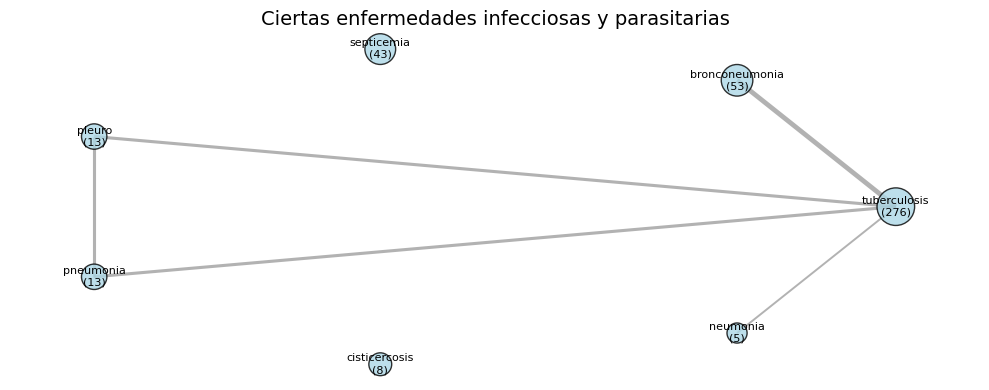

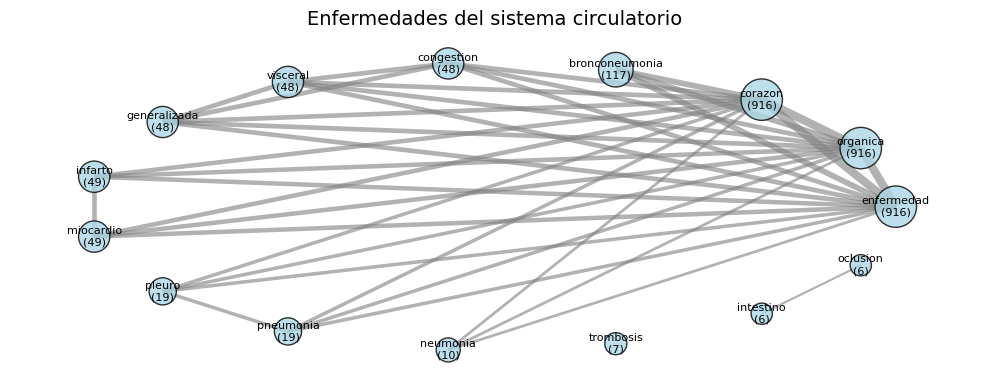

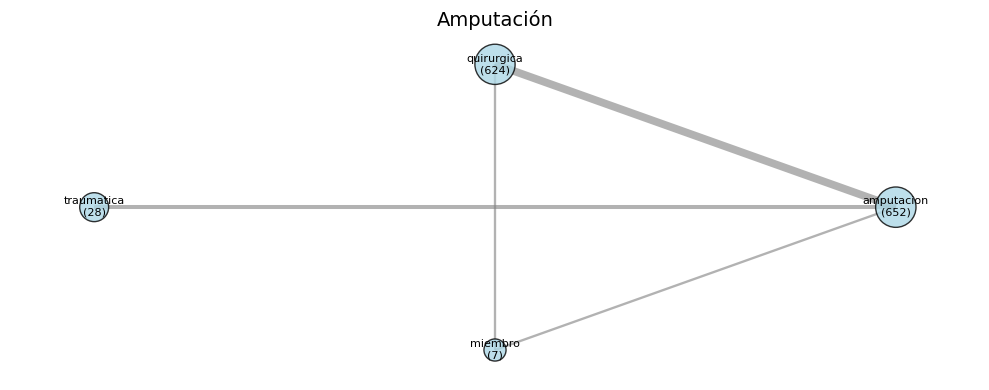

In [21]:
thr = 5
filtered = ['+','o','traumatismo','herida','arma','fuego','punzo','cortante','de','del','por',]

for clas in df_diag['Diagnostico_clasificacion'].unique():
    data = df_diag.loc[df_diag['Diagnostico_clasificacion']==clas,'Diagnostico_extendido'].value_counts()
    data = data[data>=thr]
    G = create_network_from_lists(data.index.to_list(), data.to_list(), remove_list=filtered, filter_singletons=False, sep=' ')
    
    # Obtain log10 of weight
    for node in G.nodes():
        G.nodes[node]["weight_log10"] = float(np.log10( G.nodes[node]["weight"] ))
    for node1, node2 in G.edges():
        G.edges[node1, node2]["weight_log10"] = float(np.log10( G.edges[node1, node2]["weight"] ))
    
    # Plot the graph
    plot_weighted_graph(
                        G, plot_title=clas, 
                        figsize=(10,4), font_size=8, layout='circular',
                        node_size_attribute='weight_log10', edge_width_attribute='weight_log10',
                        node_label_attribute='weight')


**Done**